# Financial Fraud Detection Model with Dashboard

**Project overview.** This notebook builds the data + machine-learning half of a fraud detection system:
it loads four transaction datasets, cleans them, stores them in a SQLite database (ETL), explores them
(EDA), engineers features, trains supervised and unsupervised fraud models, simulates real-time
monitoring with alerts, and saves everything the Streamlit dashboard (`app.py`) needs.

**How the notebook is organised**

| # | Section | What you get |
|---|---------|--------------|
| 1 | Load & overview | Shape, fraud rate, missing values, duplicates for all 4 datasets |
| 2 | Cleaning & ETL | Missing-value handling, leakage check, unified table in SQLite |
| 3 | EDA | Count plot, histogram, KDE, box plot, scatter, heatmaps, outliers |
| 4 | Feature engineering | Balance errors, binning, frequency encoding, scaling |
| 5 | Supervised models | Logistic Regression, Decision Tree, Random Forest, Gradient Boosting |
| 6 | Unsupervised models | Isolation Forest, One-Class SVM, Autoencoder |
| 7 | Graph analysis | Account network of fraud transactions |
| 8 | Gradient descent | `f(x)=x²` demo and logistic regression trained by hand |
| 9 | Real-time simulation | Micro-batch stream, alerts, adaptive (online) learning |
| 10 | Save artifacts | Model, metrics and database for the dashboard |

**Important data finding (read this first).** The four files are *not* equally useful for modelling.
`Fraud_Detection.xlsx` has a strong, learnable fraud pattern, `financial_fraud_detection_dataset.xlsx`
has a weak one, and in `credit_card_fraud_dataset.xlsx` and `synthetic_fraud_dataset1.xlsx` the fraud
labels behave like random noise. Section 3 proves this with statistical tests and Section 5 with a
cross-validated benchmark. So the **main model is trained on `Fraud_Detection.xlsx`**, and the other three
files are explored and benchmarked, not blindly merged into one model.

In [1]:
import json
import os
import sqlite3
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
PALETTE = {0: "#4C78A8", 1: "#E4572E"}            # legit = blue, fraud = red
LABELS = {0: "Legit", 1: "Fraud"}
LABEL_PALETTE = {"Legit": PALETTE[0], "Fraud": PALETTE[1]}
HUE_ORDER = ["Legit", "Fraud"]
ARTIFACTS = Path("artifacts")                       # everything the dashboard needs goes here
ARTIFACTS.mkdir(exist_ok=True)


def find_file(*names):
    """Look for a dataset in ./data, the current folder, or the upload folder."""
    for folder in [Path("data"), Path("."), Path("/mnt/user-data/uploads")]:
        for name in names:
            # accept the .xlsx name OR a .csv with the same name (spaces / underscores do not matter)
            for cand in (name, Path(name).with_suffix(".csv").name,
                         name.replace(" ", "_"), Path(name.replace(" ", "_")).with_suffix(".csv").name):
                if (folder / cand).exists():
                    return folder / cand
    raise FileNotFoundError(f"Put {names[0]} in a 'data' folder next to this notebook.")


def read_any(path):
    """Read an .xlsx or .csv dataset. In CSV files the date columns come back as text, so convert them."""
    path = Path(path)
    if path.suffix.lower() == ".csv":
        df = pd.read_csv(path)
        for c in df.columns:
            if "date" in c.lower():
                df[c] = pd.to_datetime(df[c], errors="coerce")
        return df
    return pd.read_excel(path)


def annotate_bars(ax, fmt="{:,.0f}"):
    """Write the value on top of every bar."""
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            ax.annotate(fmt.format(h), (p.get_x() + p.get_width() / 2, h),
                        ha="center", va="bottom", fontsize=9)


print("Setup done. Artifacts folder:", ARTIFACTS.resolve())

Setup done. Artifacts folder: C:\Users\Manas\Desktop\fraud_project_deliverable\fraud_project\artifacts


## 1. Loading the datasets

`pd.read_excel` reads the first sheet of each file into a DataFrame (this is the Excel version of
`pd.read_csv` from the EDA notebook). `df.shape` gives (rows, columns).

In [2]:
FILES = {
    "credit_card": find_file("credit_card_fraud_dataset.xlsx"),
    "financial":   find_file("financial_fraud_detection_dataset.xlsx"),
    "synthetic":   find_file("synthetic_fraud_dataset1.xlsx"),
    "bank":        find_file("Fraud_Detection.xlsx", "Fraud Detection.xlsx"),
}
RAW = {name: read_any(path) for name, path in FILES.items()}

for name, df in RAW.items():
    print(f"{name:12s} {df.shape[0]:>7,} rows x {df.shape[1]:>2} columns   <- {FILES[name].name}")

credit_card  100,000 rows x  7 columns   <- credit_card_fraud_dataset.csv
financial      5,000 rows x 14 columns   <- financial_fraud_detection_dataset.csv
synthetic     50,000 rows x 14 columns   <- synthetic_fraud_dataset1.csv
bank          10,127 rows x 20 columns   <- Fraud Detection.xlsx


In [3]:
# df.head(): first look at the primary dataset (Fraud_Detection.xlsx)
RAW["bank"].head()

,step,type,branch,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,unusuallogin,isFlaggedFraud,Acct type,Date of transaction,Time of day,isFraud,Column1,isFraud - Copy,DayOfWeek,DayOfWeek(new)
0,7,PAYMENT,Espana,1526.50,C1908839976,0.0,0.0,M1304522697,0.0,0.0,7,0,Savings,2018-01-03,Afternoon,Safe,7168,0.0,3.0,Wednesday
1,7,PAYMENT,Honduras,1620.17,C70432899,0.0,0.0,M252297858,0.0,0.0,2,0,Savings,2018-01-05,Night,Safe,7211,0.0,5.0,Friday
2,7,PAYMENT,Indonesia,5689.82,C332151172,0.0,0.0,M1430674428,0.0,0.0,3,0,Savings,2018-01-07,Morning,Safe,7268,0.0,7.0,Sunday
3,7,PAYMENT,Estados Unidos,2211.07,C1148172078,0.0,0.0,M650835126,0.0,0.0,13,0,Savings,2018-01-06,Afternoon,Safe,7325,0.0,6.0,Saturday
4,7,PAYMENT,Estados Unidos,824.63,C1142006014,0.0,0.0,M745868137,0.0,0.0,7,0,Savings,2018-01-06,Morning,Safe,7326,0.0,6.0,Saturday


### Dataset overview
Name of the fraud column in each file, the fraud rate, missing cells and duplicate rows
(`df.isnull().sum()` and `df.duplicated().sum()` from the EDA notebook, applied to all four files).

In [4]:
TARGET = {"credit_card": "IsFraud", "financial": "Fraudulent",
          "synthetic": "Fraud_Label", "bank": "isFraud"}


def fraud_flag(name, df):
    """1 = fraud, 0 = legit. The bank file stores the label as text ('Safe' / 'Fraud' / 'Not reviewed')."""
    t = df[TARGET[name]]
    return (t == "Fraud").astype(int) if name == "bank" else t.astype(int)


rows = []
for name, df in RAW.items():
    flag = fraud_flag(name, df)
    rows.append({
        "dataset": name, "rows": len(df), "columns": df.shape[1],
        "fraud_cases": int(flag.sum()), "fraud_rate_%": round(100 * flag.mean(), 2),
        "missing_cells": int(df.isnull().sum().sum()), "duplicate_rows": int(df.duplicated().sum()),
    })
overview = pd.DataFrame(rows).set_index("dataset")
overview

,rows,columns,fraud_cases,fraud_rate_%,missing_cells,duplicate_rows
dataset,,,,,,
credit_card,100000,7,1000,1.00,60734,0
financial,5000,14,482,9.64,2963,0
synthetic,50000,14,16067,32.13,0,0
bank,10127,20,68,0.67,58,0


**Reading the table:** the fraud rate differs a lot between files (0.7% to 32%), which is the first
warning that these files come from different sources and should not simply be stacked into one
training set.

## 2. Data cleaning and ETL

### 2.1 The primary dataset (`Fraud_Detection.xlsx`)
Things to fix before any modelling:
* the label column has a third value, `Not reviewed` (2 rows), which is neither fraud nor legit -> drop;
* a column called `isFraud - Copy` could be a **copy of the target** (data leakage) -> test it;
* `isFlaggedFraud` is constant, `Column1` is an index and the two day-of-week columns are derived from the date;
* 58 missing cells.

In [5]:
bank = RAW["bank"].copy()
print(bank["isFraud"].value_counts().to_string(), "\n")

reviewed = bank[bank["isFraud"].isin(["Safe", "Fraud"])]
same = (reviewed["isFraud - Copy"] == (reviewed["isFraud"] == "Fraud")).mean()
print(f"'isFraud - Copy' equals the label in {same:.0%} of reviewed rows  -> it is a LEAK, so it must not be a feature.")
print("isFlaggedFraud unique values:", bank["isFlaggedFraud"].unique())

isFraud
Safe            10057
Fraud              68
Not reviewed        2 

'isFraud - Copy' equals the label in 100% of reviewed rows  -> it is a LEAK, so it must not be a feature.
isFlaggedFraud unique values: [0]


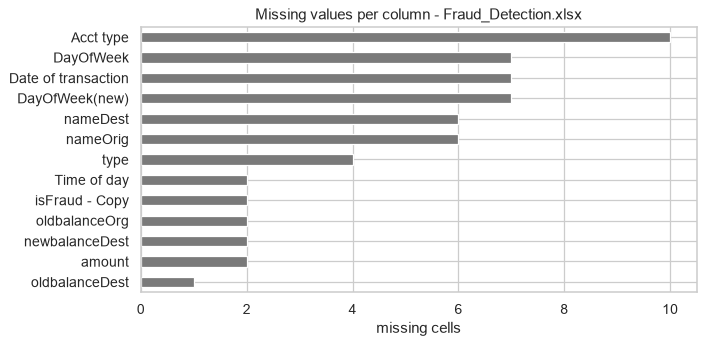

In [6]:
# Missing values per column (df.isnull().sum())
missing = bank.isnull().sum()
missing = missing[missing > 0].sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
missing.plot.barh(ax=ax, color="#7A7A7A")
ax.set_title("Missing values per column - Fraud_Detection.xlsx")
ax.set_xlabel("missing cells")
plt.tight_layout()
plt.show()

### 2.2 Which imputation method is best? (mean vs median vs KNN)
The EDA notebook lists several imputation methods. Here we test three of them honestly: hide 5% of the
known `amount` values, fill them back with each method, and measure the error (on a log-like `arcsinh`
scale, because amounts are very skewed).

In [7]:
from sklearn.impute import KNNImputer

def knn_impute(frame, cols, k=5):
    """KNN imputation on an arcsinh-compressed, standardised copy; values are returned on the original scale."""
    z = np.arcsinh(frame[cols])
    mu, sd = z.mean(), z.std()
    filled = KNNImputer(n_neighbors=k).fit_transform((z - mu) / sd)
    return pd.DataFrame(np.sinh(filled * sd.to_numpy() + mu.to_numpy()), columns=cols, index=frame.index)


num_cols = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "unusuallogin"]
complete = bank.dropna(subset=num_cols)[num_cols].reset_index(drop=True)

rng = np.random.default_rng(RANDOM_STATE)
mask = rng.random(len(complete)) < 0.05
truth = complete.loc[mask, "amount"].to_numpy()
masked = complete.copy()
masked.loc[mask, "amount"] = np.nan

preds = {
    "mean":   np.full(mask.sum(), masked["amount"].mean()),
    "median": np.full(mask.sum(), masked["amount"].median()),
    "KNN (k=5)": knn_impute(masked, num_cols).loc[mask, "amount"].to_numpy(),
}
imputation_mae = pd.Series({k: np.abs(np.arcsinh(v) - np.arcsinh(truth)).mean() for k, v in preds.items()},
                           name="MAE (arcsinh scale)").round(3)
imputation_mae.to_frame()

,MAE (arcsinh scale)
mean,2.185
median,1.771
KNN (k=5),0.789


The lower the error the better. Mean imputation is pulled up by a few huge transactions, the median is more
robust, and **KNN is clearly the most accurate** because it uses the other columns of similar transactions.
So we use **KNN for the numeric columns**, the mode (most frequent value) for categories and forward-fill
for dates.

In [8]:
# --- apply the cleaning to the primary dataset ---
bank = bank[bank["isFraud"].isin(["Safe", "Fraud"])].copy()                      # drop 'Not reviewed'
bank["is_fraud"] = (bank["isFraud"] == "Fraud").astype(int)
bank = bank.drop(columns=["isFraud", "isFraud - Copy", "isFlaggedFraud", "Column1", "DayOfWeek", "DayOfWeek(new)"])
bank = bank.rename(columns={"Acct type": "acct_type", "Date of transaction": "date", "Time of day": "time_of_day"})

money = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
filled = knn_impute(bank, money + ["unusuallogin"])
for c in money:
    bank[c] = bank[c].fillna(filled[c])                                            # KNN imputation (only the gaps)
for c in ["type", "acct_type", "time_of_day"]:
    bank[c] = bank[c].fillna(bank[c].mode()[0])                                    # mode imputation
bank["date"] = bank["date"].ffill().bfill()                                         # forward fill
bank[["nameOrig", "nameDest"]] = bank[["nameOrig", "nameDest"]].fillna("UNKNOWN")

before = len(bank)
bank = bank.drop_duplicates().reset_index(drop=True)                                # duplicated().sum() == 0 here
bank.insert(0, "txn_id", [f"BNK-{i:06d}" for i in range(1, len(bank) + 1)])

print(f"rows: {before:,} -> {len(bank):,}   missing cells left: {int(bank.isnull().sum().sum())}")
print(f"fraud cases: {bank['is_fraud'].sum()}  ({100 * bank['is_fraud'].mean():.2f}%)")
bank.head()

rows: 10,125 -> 10,125   missing cells left: 0
fraud cases: 68  (0.67%)


,txn_id,step,type,branch,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,unusuallogin,acct_type,date,time_of_day,is_fraud
0,BNK-000001,7,PAYMENT,Espana,1526.50,C1908839976,0.0,0.0,M1304522697,0.0,0.0,7,Savings,2018-01-03,Afternoon,0
1,BNK-000002,7,PAYMENT,Honduras,1620.17,C70432899,0.0,0.0,M252297858,0.0,0.0,2,Savings,2018-01-05,Night,0
2,BNK-000003,7,PAYMENT,Indonesia,5689.82,C332151172,0.0,0.0,M1430674428,0.0,0.0,3,Savings,2018-01-07,Morning,0
3,BNK-000004,7,PAYMENT,Estados Unidos,2211.07,C1148172078,0.0,0.0,M650835126,0.0,0.0,13,Savings,2018-01-06,Afternoon,0
4,BNK-000005,7,PAYMENT,Estados Unidos,824.63,C1142006014,0.0,0.0,M745868137,0.0,0.0,7,Savings,2018-01-06,Morning,0


### 2.3 The other three datasets
They have no missing values and no duplicates, so cleaning is only type fixing and renaming the label to
a common name, `is_fraud`. Native column names are kept so the EDA stays recognisable.

In [9]:
credit = RAW["credit_card"].rename(columns={"IsFraud": "is_fraud"}).drop_duplicates().reset_index(drop=True)
financial = RAW["financial"].rename(columns={"Fraudulent": "is_fraud"}).drop_duplicates().reset_index(drop=True)
synthetic = RAW["synthetic"].rename(columns={"Fraud_Label": "is_fraud"}).drop_duplicates().reset_index(drop=True)

CLEAN = {"credit_card": credit, "financial": financial, "synthetic": synthetic, "bank": bank}

# Per-dataset settings reused by the EDA, the benchmark and the dashboard
DATASETS = {
    "credit_card": dict(label="Credit card (credit_card_fraud_dataset)", amount="Amount",
                        id_cols=["TransactionID"], category="Location", scatter_y="MerchantID"),
    "financial":   dict(label="Financial (financial_fraud_detection_dataset)", amount="Transaction_Amount",
                        id_cols=["Transaction_ID", "Customer_ID"], category="Suspicious_Keyword", scatter_y="Average_Spend"),
    "synthetic":   dict(label="Synthetic (synthetic_fraud_dataset1)", amount="Transaction_Amount",
                        id_cols=["Transaction_ID", "User_ID"], category="Transaction_Type", scatter_y="Account_Balance"),
    "bank":        dict(label="Bank transactions (Fraud_Detection)  [PRIMARY]", amount="amount",
                        id_cols=["txn_id", "nameOrig", "nameDest"], category="type", scatter_y="oldbalanceOrg"),
}
for k, v in CLEAN.items():
    print(f"{k:12s} {v.shape}  fraud rate {100 * v['is_fraud'].mean():.2f}%")

credit_card  (100000, 7)  fraud rate 1.00%
financial    (5000, 14)  fraud rate 9.64%
synthetic    (50000, 14)  fraud rate 32.13%
bank         (10125, 16)  fraud rate 0.67%


### 2.4 One unified table + SQLite (the ETL step of the project plan)
Different files, different columns. We map the columns that exist in (almost) all of them to one schema:
`date, amount, txn_type, category, location, device`. Where a file has no such column we write `Unknown`.
The unified table is for **overview, comparison and dashboard heatmaps**; it is not used to train one
combined model (see the data finding at the top).

In [10]:
def harmonize(name, df):
    out = pd.DataFrame(index=df.index)
    out["source"] = name
    id_col = next(c for c in ["txn_id", "TransactionID", "Transaction_ID"] if c in df.columns)
    out["txn_id"] = df[id_col].astype(str)
    if name == "credit_card":
        m = dict(date="TransactionDate", amount="Amount", txn_type="TransactionType", location="Location")
    elif name == "financial":
        m = dict(date="Transaction_Date", amount="Transaction_Amount", txn_type="Payment_Method",
                 category="Merchant_Category", location="Location", device="Device_Type")
    elif name == "synthetic":
        m = dict(date="Date", amount="Transaction_Amount", txn_type="Transaction_Type",
                 category="Merchant_Category", location="Location", device="Device_Type")
    else:
        m = dict(date="date", amount="amount", txn_type="type", location="branch")
    for col in ["date", "amount", "txn_type", "category", "location", "device"]:
        out[col] = df[m[col]] if col in m else "Unknown"
    out["is_fraud"] = df["is_fraud"].astype(int)
    out["date"] = pd.to_datetime(out["date"])
    out["weekday"] = out["date"].dt.day_name()
    out["month"] = out["date"].dt.month
    return out


UNIFIED = pd.concat([harmonize(n, d) for n, d in CLEAN.items()], ignore_index=True)
print(UNIFIED.shape)
UNIFIED.sample(5, random_state=1)

(165125, 11)


,source,txn_id,date,amount,txn_type,category,location,device,is_fraud,weekday,month
7840,credit_card,7841,NaT,439.14,refund,Unknown,San Diego,Unknown,0,NaN,NaN
14764,credit_card,14765,NaT,945.82,refund,Unknown,New York,Unknown,0,NaN,NaN
40311,credit_card,40312,NaT,4556.85,refund,Unknown,New York,Unknown,0,NaN,NaN
163477,bank,BNK-008478,2018-01-07,165969.93,TRANSFER,Unknown,Estados Unidos,Unknown,0,Sunday,1.0
152389,synthetic,TXN_33160,2023-11-21,2.35,Online,Clothing,London,Tablet,0,Tuesday,11.0


In [11]:
# ETL: load the cleaned data into SQLite (same pattern as the project plan: sqlite3 + df.to_sql)
DB_PATH = ARTIFACTS / "fraud_detection.db"
conn = sqlite3.connect(DB_PATH)
UNIFIED.to_sql("transactions", conn, if_exists="replace", index=False)
for name, df in CLEAN.items():
    df.to_sql(f"{name}_clean", conn, if_exists="replace", index=False)
conn.commit()

query = """
SELECT source,
       COUNT(*)                                        AS txns,
       SUM(is_fraud)                                   AS fraud_cases,
       ROUND(100.0 * AVG(is_fraud), 2)                 AS fraud_pct,
       ROUND(SUM(CASE WHEN is_fraud = 1 THEN amount END), 0) AS fraud_amount
FROM transactions
GROUP BY source
ORDER BY fraud_pct DESC
"""
print("ETL process completed ->", DB_PATH)
etl_check = pd.read_sql_query(query, conn)
conn.close()
etl_check

ETL process completed -> artifacts\fraud_detection.db


,source,txns,fraud_cases,fraud_pct,fraud_amount
0,synthetic,50000,16067,32.13,1601618.0
1,financial,5000,482,9.64,39521.0
2,credit_card,100000,1000,1.00,2517164.0
3,bank,10125,68,0.67,36275527.0


## 3. Exploratory Data Analysis (EDA)

Graphs used (same toolkit as the EDA notebook): **count plot, histogram, KDE, box plot, scatter plot,
correlation heatmap**, plus fraud heatmaps for the dashboard. Blue = legit, red = fraud everywhere.

### 3.1 Primary dataset - class balance (count plot)

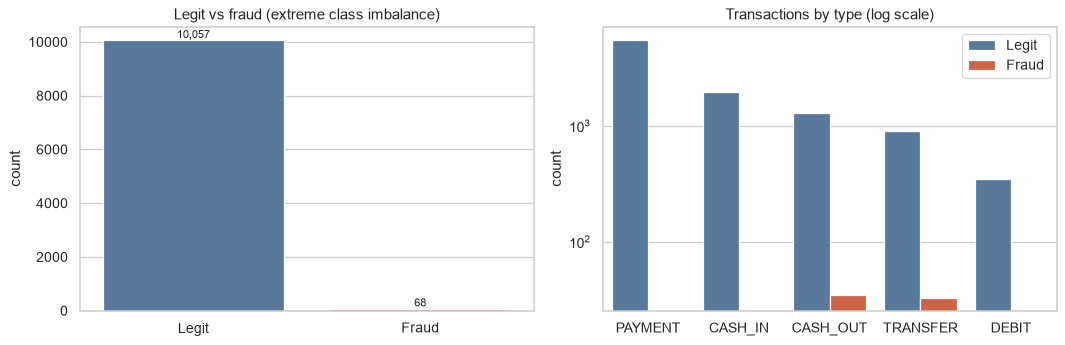

,txns,fraud,fraud_rate
type,,,
TRANSFER,946,33,3.49
CASH_OUT,1336,35,2.62
CASH_IN,1953,0,0.00
DEBIT,346,0,0.00
PAYMENT,5544,0,0.00


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Count plot: how many legit vs fraud?
sns.countplot(x=bank["is_fraud"].map(LABELS), hue=bank["is_fraud"].map(LABELS),
              order=["Legit", "Fraud"], palette={"Legit": PALETTE[0], "Fraud": PALETTE[1]},
              legend=False, ax=ax[0])
annotate_bars(ax[0])
ax[0].set_title("Legit vs fraud (extreme class imbalance)")
ax[0].set_xlabel("")

# Count plot by transaction type, split by class (log scale because fraud is tiny)
sns.countplot(data=bank, x="type", hue=bank["is_fraud"].map(LABELS), palette={"Legit": PALETTE[0], "Fraud": PALETTE[1]},
              order=bank["type"].value_counts().index, ax=ax[1])
ax[1].set_yscale("log")
ax[1].set_title("Transactions by type (log scale)")
ax[1].set_xlabel("")
ax[1].legend(title="")
plt.tight_layout()
plt.show()

rate_by_type = (bank.groupby("type")["is_fraud"].agg(["size", "sum", "mean"])
                .rename(columns={"size": "txns", "sum": "fraud", "mean": "fraud_rate"}).sort_values("fraud_rate", ascending=False))
rate_by_type["fraud_rate"] = (100 * rate_by_type["fraud_rate"]).round(2)
rate_by_type

**Insight:** fraud appears only in `TRANSFER` and `CASH_OUT`. Payments, cash-ins and debits are never
fraudulent in this data, which is the classic account-takeover pattern (move the money out, then cash it out).
Because only ~0.7% of rows are fraud, **accuracy is a useless metric** (always predicting "legit" scores 99.3%);
we will use precision, recall, F1 and PR-AUC.

### 3.2 Distributions - histogram + KDE
Amounts span many orders of magnitude, so we plot `log(1 + amount)`. The curve over the bars is the KDE
(smooth density estimate). `common_norm=False` normalises each class separately, otherwise the 68 fraud
cases would be invisible next to 10,000 legit ones.

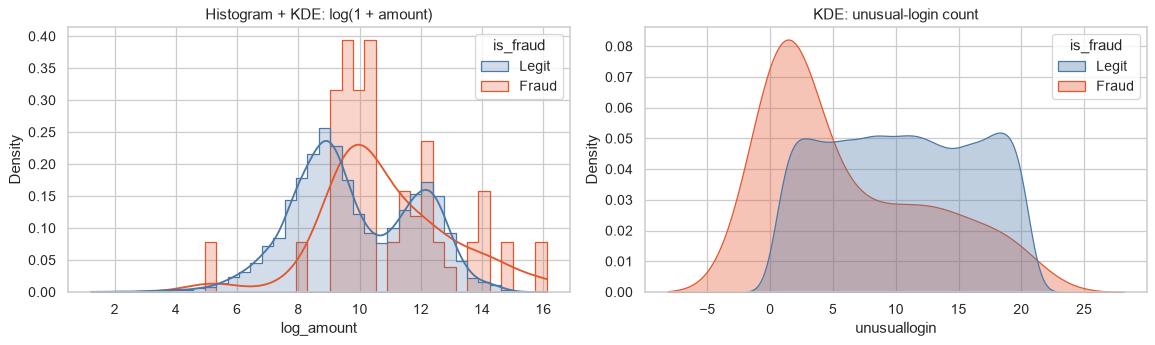

amount          unusuallogin       
              mean   median         mean median
is_fraud                                       
Fraud     533463.6  28644.8          6.1    2.0
Legit     102003.9  12702.7         10.5   11.0

In [13]:
bank["log_amount"] = np.log1p(bank["amount"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(data=bank, x="log_amount", hue=bank["is_fraud"].map(LABELS), hue_order=HUE_ORDER, palette=LABEL_PALETTE,
             kde=True, stat="density", common_norm=False, element="step", bins=40, ax=ax[0])
ax[0].set_title("Histogram + KDE: log(1 + amount)")

sns.kdeplot(data=bank, x="unusuallogin", hue=bank["is_fraud"].map(LABELS), hue_order=HUE_ORDER, palette=LABEL_PALETTE,
            common_norm=False, fill=True, alpha=0.35, ax=ax[1])
ax[1].set_title("KDE: unusual-login count")
plt.tight_layout()
plt.show()

bank.groupby(bank["is_fraud"].map(LABELS))[["amount", "unusuallogin"]].agg(["mean", "median"]).round(1)

**Insight:** the table shows that, on average, fraudulent transactions are much larger (a heavy right tail in
the red curve) and come with *fewer* unusual-login events than legit ones.

### 3.3 Outliers - box plot, Z-score and IQR
* **Box plot**: dots beyond the whiskers are potential outliers.
* **Z-score**: a value is unusual if |Z| > 3.
* **IQR rule**: below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`.

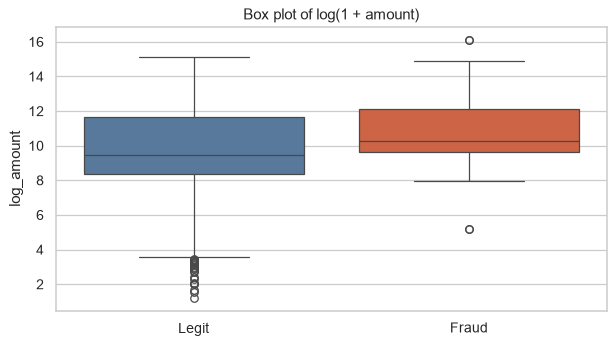

,rows,|Z| > 3,IQR outliers
Legit,10057,184,1051
Fraud,68,2,10


In [14]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=bank, x=bank["is_fraud"].map(LABELS), y="log_amount", hue=bank["is_fraud"].map(LABELS),
            order=["Legit", "Fraud"], palette={"Legit": PALETTE[0], "Fraud": PALETTE[1]}, legend=False, ax=ax)
ax.set_title("Box plot of log(1 + amount)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()


def outlier_report(s):
    z = np.abs(stats.zscore(s))
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return {"rows": len(s), "|Z| > 3": int((z > 3).sum()), "IQR outliers": int(((s < low) | (s > high)).sum())}


pd.DataFrame({LABELS[k]: outlier_report(g["amount"]) for k, g in bank.groupby("is_fraud")}).T

**Decision:** we do **not** delete these outliers. In fraud detection the unusually large transactions are
often exactly the fraud we are trying to catch; removing them would remove the signal. Instead we compress
the scale (log / `arcsinh`) where a model needs it.

### 3.4 Relationships - scatter plot and correlation heatmap

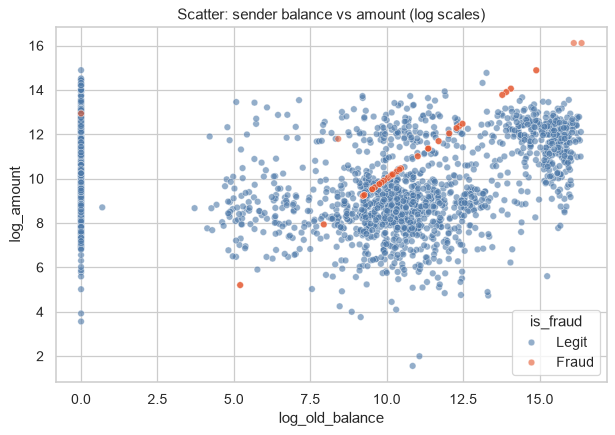

In [15]:
sample = pd.concat([bank[bank["is_fraud"] == 0].sample(2000, random_state=RANDOM_STATE), bank[bank["is_fraud"] == 1]])
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=sample.assign(log_old_balance=np.log1p(sample["oldbalanceOrg"])),
                x="log_old_balance", y="log_amount", hue=sample["is_fraud"].map(LABELS), hue_order=HUE_ORDER,
                palette=LABEL_PALETTE, alpha=0.6, s=28, ax=ax)
ax.set_title("Scatter: sender balance vs amount (log scales)")
plt.tight_layout()
plt.show()

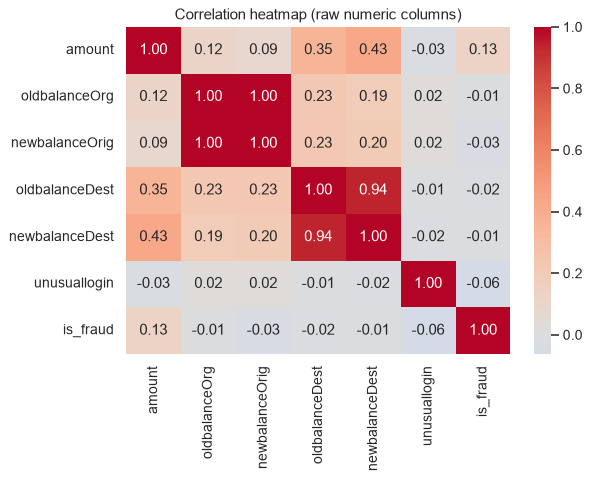

In [16]:
corr = bank[["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "unusuallogin", "is_fraud"]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation heatmap (raw numeric columns)")
plt.tight_layout()
plt.show()

**Insight:** the raw columns have *weak* linear correlation with fraud. The real signal is in the
*relationship* between columns (does the balance change by the amount sent?), which is why Section 4 builds
new features.

### 3.5 Fraud heatmaps (also used in the dashboard)

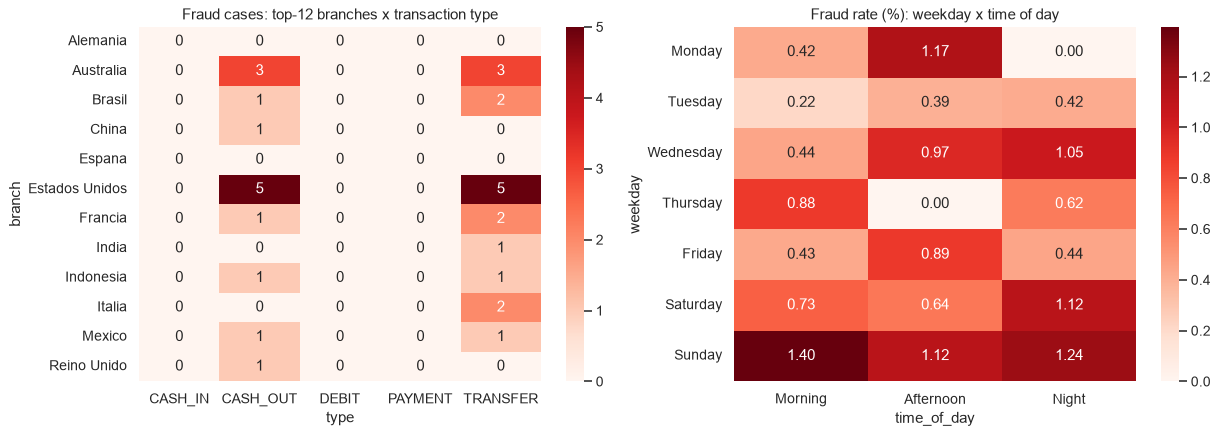

In [17]:
top_branches = bank["branch"].value_counts().head(12).index
fraud_by_branch_type = (bank[bank["branch"].isin(top_branches)]
                        .pivot_table(index="branch", columns="type", values="is_fraud", aggfunc="sum", fill_value=0)
                        .astype(int))
bank["weekday"] = bank["date"].dt.day_name()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
rate_weekday_tod = (bank.pivot_table(index="weekday", columns="time_of_day", values="is_fraud", aggfunc="mean")
                    .reindex(weekday_order)[["Morning", "Afternoon", "Night"]] * 100)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(fraud_by_branch_type, annot=True, fmt="d", cmap="Reds", ax=ax[0])
ax[0].set_title("Fraud cases: top-12 branches x transaction type")
sns.heatmap(rate_weekday_tod, annot=True, fmt=".2f", cmap="Reds", ax=ax[1])
ax[1].set_title("Fraud rate (%): weekday x time of day")
plt.tight_layout()
plt.show()

**Caution:** there are only 68 fraud cases in total, so each heatmap cell rests on a handful of them. A pattern
such as "Sunday looks riskier" could be chance; treat it as a hint to investigate, not a conclusion.

### 3.6 Binning with `pd.cut` - fraud rate by amount band
Binning turns a continuous column into groups (the EDA notebook does this for age groups).

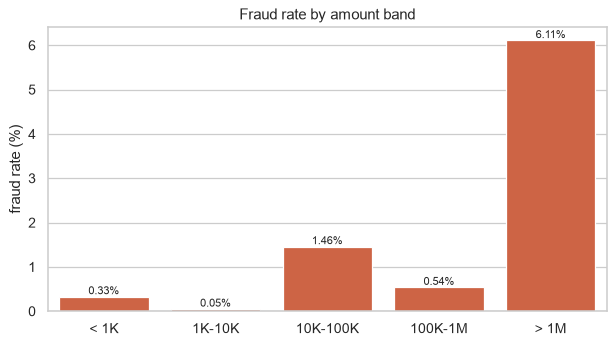

In [18]:
bank["amount_band"] = pd.cut(bank["amount"], bins=[-1, 1_000, 10_000, 100_000, 1_000_000, np.inf],
                             labels=["< 1K", "1K-10K", "10K-100K", "100K-1M", "> 1M"])
band = bank.groupby("amount_band", observed=True)["is_fraud"].agg(["size", "mean"])
band["fraud_rate_%"] = (100 * band["mean"]).round(2)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=band.index.astype(str), y=band["fraud_rate_%"], color=PALETTE[1], ax=ax)
annotate_bars(ax, "{:.2f}%")
ax.set_title("Fraud rate by amount band")
ax.set_xlabel("")
ax.set_ylabel("fraud rate (%)")
plt.tight_layout()
plt.show()

### 3.7 The other three datasets
One panel per dataset: count plot, histogram + KDE, box plot, scatter, correlation heatmap and the fraud
rate for one category. The question we ask of each file is simple: **do fraud and legit transactions look
different at all?**

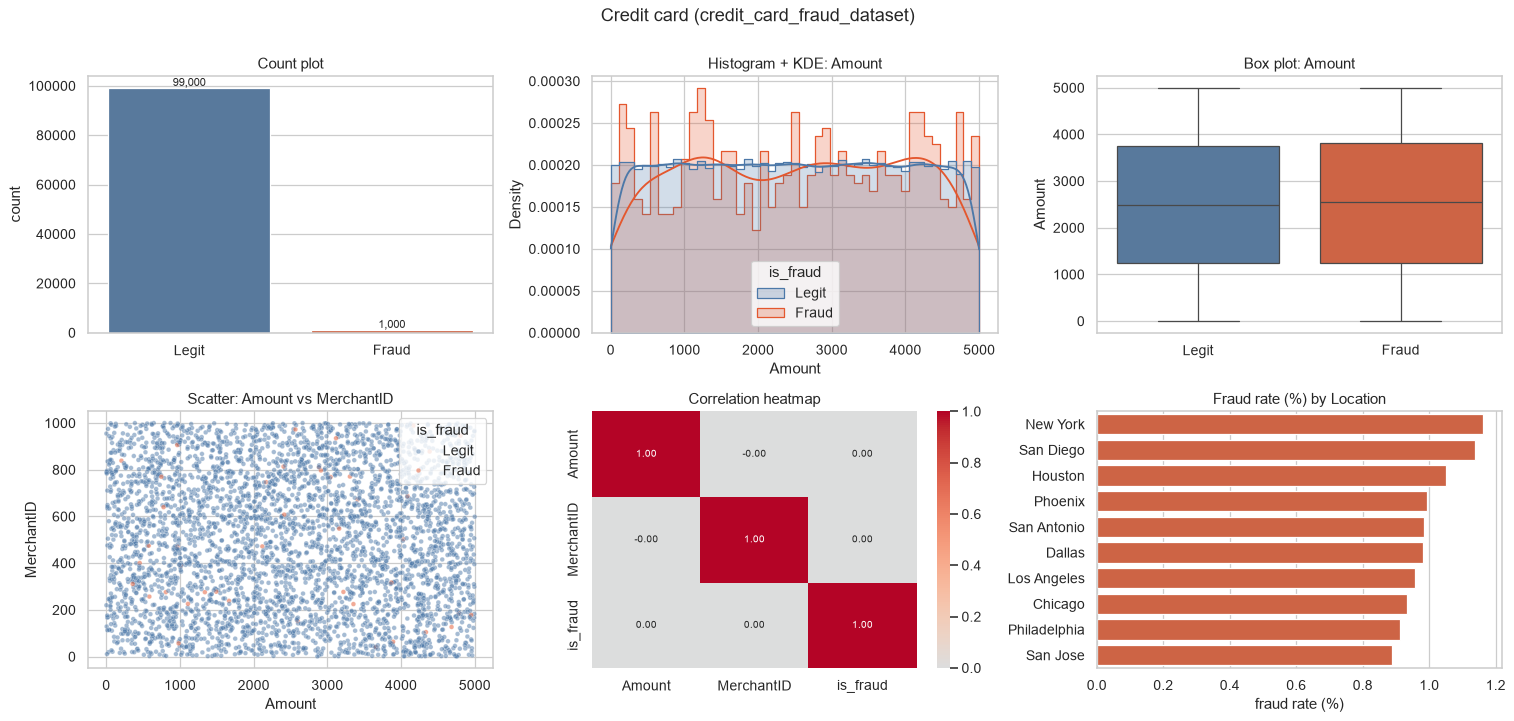

In [19]:
def quick_eda(name):
    cfg, df = DATASETS[name], CLEAN[name]
    amt = cfg["amount"]
    use_log = df[amt].skew() > 2
    plot_df = df.assign(_amt=np.log1p(df[amt]) if use_log else df[amt])
    amt_label = f"log(1+{amt})" if use_log else amt
    fig, axes = plt.subplots(2, 3, figsize=(17, 8))
    fig.suptitle(cfg["label"], fontsize=14, y=1.0)

    sns.countplot(x=df["is_fraud"].map(LABELS), hue=df["is_fraud"].map(LABELS), order=["Legit", "Fraud"],
                  palette={"Legit": PALETTE[0], "Fraud": PALETTE[1]}, legend=False, ax=axes[0, 0])
    annotate_bars(axes[0, 0]); axes[0, 0].set_title("Count plot"); axes[0, 0].set_xlabel("")

    sns.histplot(data=plot_df, x="_amt", hue=df["is_fraud"].map(LABELS), hue_order=HUE_ORDER, palette=LABEL_PALETTE,
                 kde=True, stat="density", common_norm=False, element="step", ax=axes[0, 1])
    axes[0, 1].set_title(f"Histogram + KDE: {amt_label}"); axes[0, 1].set_xlabel(amt_label)

    sns.boxplot(data=plot_df, x=df["is_fraud"].map(LABELS), y="_amt", hue=df["is_fraud"].map(LABELS), order=["Legit", "Fraud"],
                palette={"Legit": PALETTE[0], "Fraud": PALETTE[1]}, legend=False, ax=axes[0, 2])
    axes[0, 2].set_title(f"Box plot: {amt_label}"); axes[0, 2].set_xlabel(""); axes[0, 2].set_ylabel(amt_label)

    s = df.sample(min(len(df), 4000), random_state=RANDOM_STATE)
    sns.scatterplot(data=s, x=amt, y=cfg["scatter_y"], hue=s["is_fraud"].map(LABELS), hue_order=HUE_ORDER,
                    palette=LABEL_PALETTE, alpha=0.5, s=14, ax=axes[1, 0])
    axes[1, 0].set_title(f"Scatter: {amt} vs {cfg['scatter_y']}")

    num = df.select_dtypes("number")
    num = num[[c for c in num.columns if c not in cfg["id_cols"]]]
    sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1, 1], annot_kws={"size": 8})
    axes[1, 1].set_title("Correlation heatmap")

    cat = cfg["category"]
    rate = (100 * df.groupby(cat)["is_fraud"].mean()).sort_values(ascending=False).head(10)
    sns.barplot(x=rate.values, y=rate.index.astype(str), color=PALETTE[1], ax=axes[1, 2])
    axes[1, 2].set_title(f"Fraud rate (%) by {cat}"); axes[1, 2].set_xlabel("fraud rate (%)"); axes[1, 2].set_ylabel("")
    plt.tight_layout()
    plt.show()


quick_eda("credit_card")

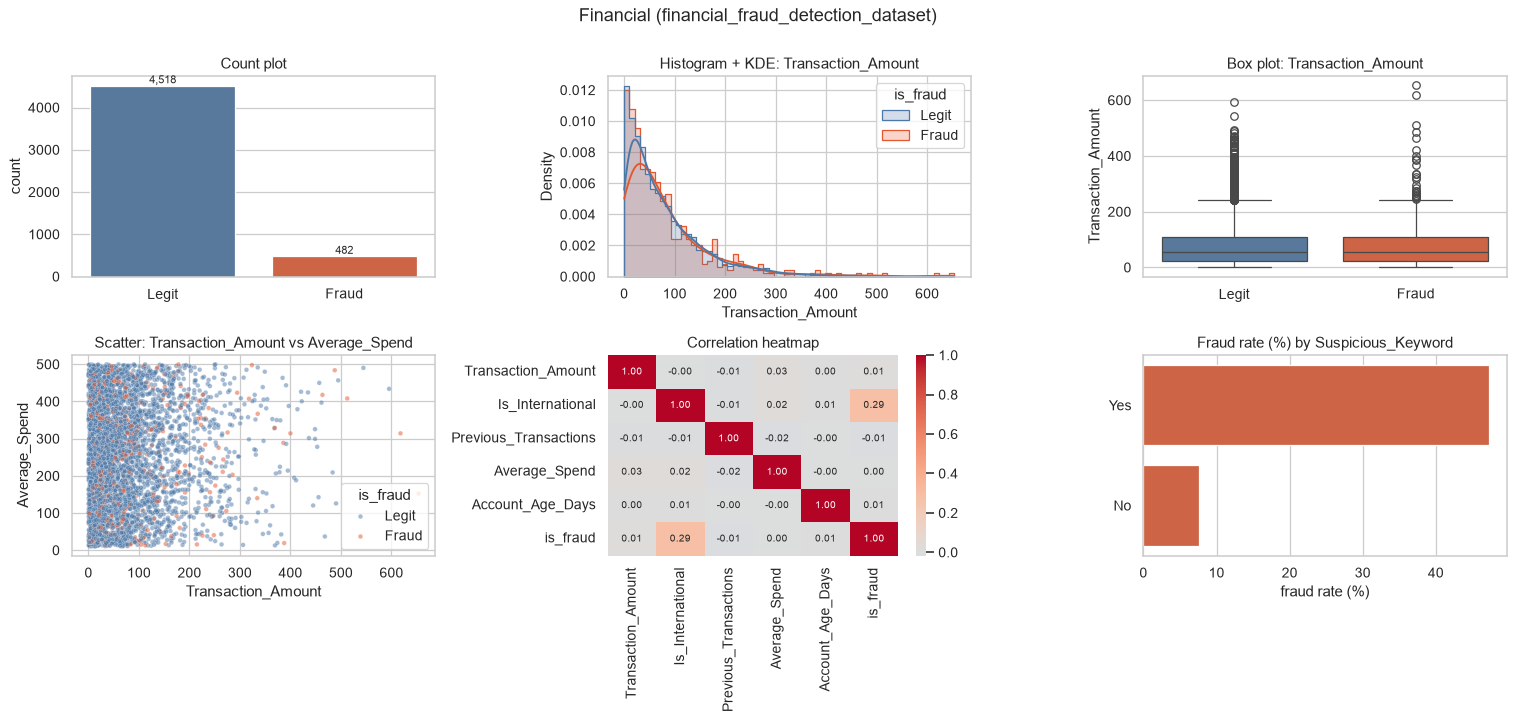

In [20]:
quick_eda("financial")

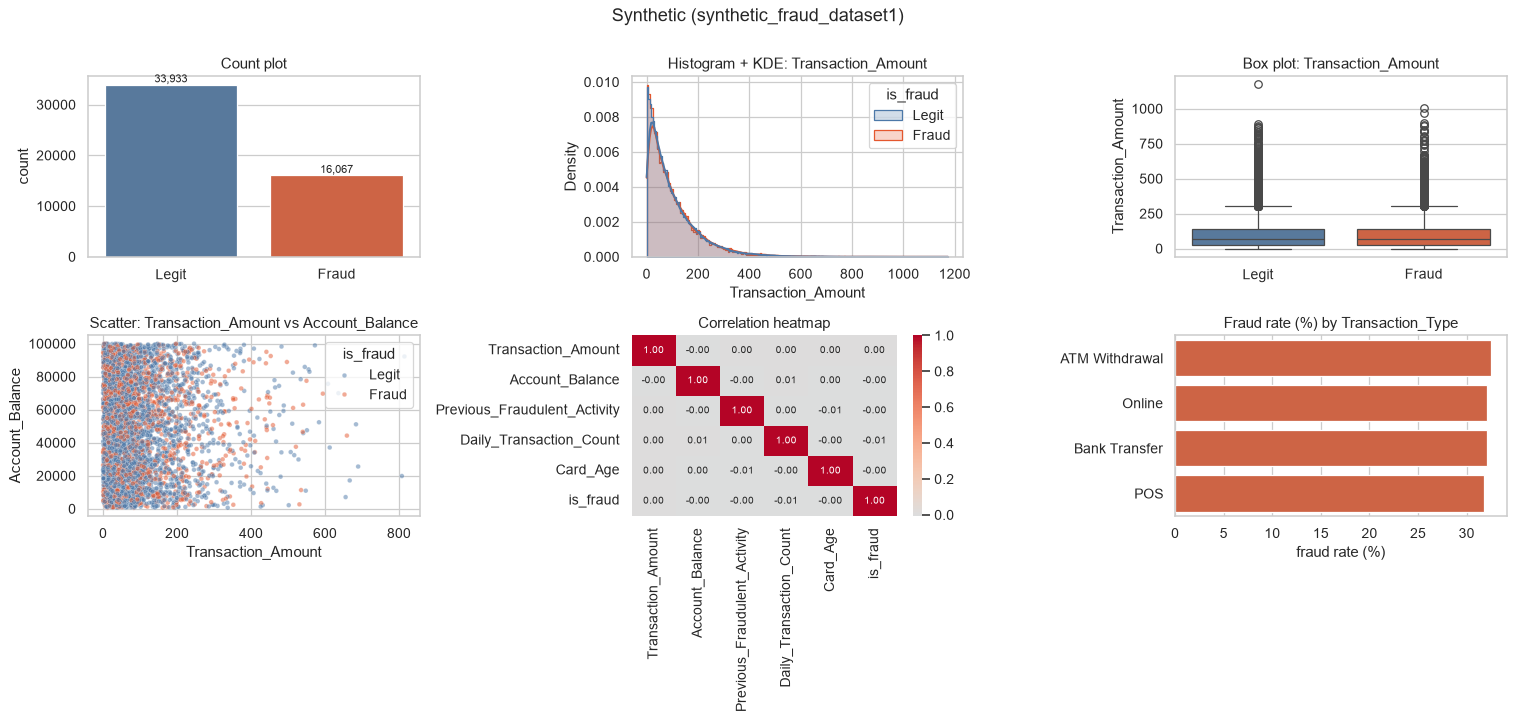

In [21]:
quick_eda("synthetic")

### 3.8 Is there any signal at all? Statistical tests
For every column we test whether its values differ between fraud and legit transactions
(**Mann-Whitney U** for numbers, **chi-square** for categories). A tiny p-value means a real difference.
If a dataset has *no* small p-values, its fraud labels carry no learnable pattern.

In [22]:
from scipy.stats import chi2_contingency, mannwhitneyu


def association_table(name):
    df, y = CLEAN[name], CLEAN[name]["is_fraud"]
    skip = set(DATASETS[name]["id_cols"]) | {"is_fraud", "log_amount", "amount_band", "weekday"}
    rows = []
    for c in df.columns:
        if c in skip:
            continue
        s = df[c]
        series = {}
        if pd.api.types.is_datetime64_any_dtype(s):
            series = {f"{c} (weekday)": s.dt.dayofweek.astype(str), f"{c} (month)": s.dt.month.astype(str)}
        else:
            series = {c: s}
        for col, v in series.items():
            if pd.api.types.is_numeric_dtype(v) and v.nunique() > 20:
                p, test = mannwhitneyu(v[y == 1], v[y == 0]).pvalue, "Mann-Whitney U"
            else:
                v = v.astype(str)
                top = v.value_counts().head(30).index
                v = v.where(v.isin(top), "other")
                p, test = chi2_contingency(pd.crosstab(v, y))[1], "Chi-square"
            rows.append({"dataset": name, "feature": col, "test": test, "p_value": p})
    return pd.DataFrame(rows)


assoc = pd.concat([association_table(n) for n in CLEAN], ignore_index=True)
signal_summary = (assoc.groupby("dataset")
                  .agg(features_tested=("feature", "size"),
                       significant_p_below_0_01=("p_value", lambda p: int((p < 0.01).sum())),
                       smallest_p=("p_value", "min"))
                  .assign(smallest_p=lambda d: d["smallest_p"].map(lambda v: f"{v:.2e}")))
signal_summary

,features_tested,significant_p_below_0_01,smallest_p
dataset,,,
bank,13,6,4.29e-51
credit_card,6,0,5.24e-01
financial,12,2,3.62e-98
synthetic,12,0,2.82e-01


In [23]:
# the strongest features per dataset
assoc.sort_values(["dataset", "p_value"]).groupby("dataset").head(3).assign(p_value=lambda d: d["p_value"].map(lambda v: f"{v:.2e}")).reset_index(drop=True)

,dataset,feature,test,p_value
0,bank,type,Chi-square,4.29e-51
1,bank,newbalanceOrig,Mann-Whitney U,1.84e-17
2,bank,unusuallogin,Mann-Whitney U,2.88e-10
3,credit_card,TransactionDate (month),Chi-square,5.24e-01
4,credit_card,Location,Chi-square,5.78e-01
5,credit_card,Amount,Mann-Whitney U,6.58e-01
6,financial,Suspicious_Keyword,Chi-square,3.62e-98
7,financial,Is_International,Chi-square,2.18e-91
8,financial,Previous_Transactions,Mann-Whitney U,3.01e-01
9,synthetic,Date (weekday),Chi-square,2.82e-01


**Reading the result:** `bank` has several columns whose values clearly differ between fraud and legit, and
`financial` has two strong ones (`Suspicious_Keyword` and `Is_International`). `credit_card` and `synthetic`
have none: their smallest p-values are around 0.2 to 0.3, which is what you get when the fraud label is
assigned *at random*. A model cannot learn a pattern that is not in the data, and Section 5
confirms it. This is why the main model uses the bank dataset.

## 4. Feature engineering (primary dataset)

*Feature engineering* means creating new, more useful columns from existing ones.

| Feature | Idea |
|---------|------|
| `err_orig` = old balance - amount - new balance | For a normal transaction this is 0. A non-zero error means the books don't add up |
| `err_dest` = old dest. balance + amount - new dest. balance | Same check for the receiving account |
| `orig_emptied` | Sender balance dropped to exactly 0 (typical of account draining) |
| `amount_to_balance` | What share of the balance is being moved |
| `log_amount` | Compresses the huge amount range |
| `type_*` | One-hot encoding of the 5 transaction types |
| `time_of_day`, `is_weekend` | Behavioural timing features (label/ordinal encoding) |
| `branch_freq` | **Frequency encoding**: each branch replaced by its share of all transactions (this uses no fraud labels, so there is no leakage) |

The function below is also copied into `app.py`, so the dashboard builds exactly the same features for a
new transaction.

In [24]:
TYPES = ["CASH_IN", "CASH_OUT", "DEBIT", "PAYMENT", "TRANSFER"]
TOD_MAP = {"Morning": 0, "Afternoon": 1, "Night": 2}
MONEY_COLS = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "err_orig", "err_dest"]
LOG_COLS = MONEY_COLS + ["amount_to_balance"]          # heavy-tailed columns


def engineer_features(df, branch_freq=None):
    out = pd.DataFrame(index=df.index)
    out["amount"] = df["amount"]
    out["log_amount"] = np.log1p(df["amount"])
    for c in ["oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]:
        out[c] = df[c]
    out["err_orig"] = df["oldbalanceOrg"] - df["amount"] - df["newbalanceOrig"]
    out["err_dest"] = df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]
    out["orig_emptied"] = (df["newbalanceOrig"] == 0).astype(int)
    out["amount_to_balance"] = df["amount"] / (df["oldbalanceOrg"] + 1)
    out["unusuallogin"] = df["unusuallogin"]
    for t in TYPES:
        out[f"type_{t}"] = (df["type"] == t).astype(int)
    out["time_of_day"] = df["time_of_day"].map(TOD_MAP)
    out["is_weekend"] = df["date"].dt.dayofweek.isin([5, 6]).astype(int)
    if branch_freq is None:
        branch_freq = df["branch"].value_counts(normalize=True)
    out["branch_freq"] = df["branch"].map(branch_freq).fillna(0.0)
    return out


BRANCH_FREQ = bank["branch"].value_counts(normalize=True)
X = engineer_features(bank, BRANCH_FREQ)
y = bank["is_fraud"]
FEATURES = list(X.columns)
print(f"{len(FEATURES)} features:", FEATURES)
X.head()

19 features: ['amount', 'log_amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'err_orig', 'err_dest', 'orig_emptied', 'amount_to_balance', 'unusuallogin', 'type_CASH_IN', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER', 'time_of_day', 'is_weekend', 'branch_freq']


,amount,log_amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,err_orig,err_dest,orig_emptied,amount_to_balance,unusuallogin,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,time_of_day,is_weekend,branch_freq
0,1526.50,7.331388,0.0,0.0,0.0,0.0,-1526.50,1526.50,1,1526.50,7,0,0,0,1,0,1,0,0.019062
1,1620.17,7.390903,0.0,0.0,0.0,0.0,-1620.17,1620.17,1,1620.17,2,0,0,0,1,0,2,0,0.018074
2,5689.82,8.646610,0.0,0.0,0.0,0.0,-5689.82,5689.82,1,5689.82,3,0,0,0,1,0,0,1,0.031111
3,2211.07,7.701684,0.0,0.0,0.0,0.0,-2211.07,2211.07,1,2211.07,13,0,0,0,1,0,1,1,0.126617
4,824.63,6.716147,0.0,0.0,0.0,0.0,-824.63,824.63,1,824.63,7,0,0,0,1,0,0,1,0.126617


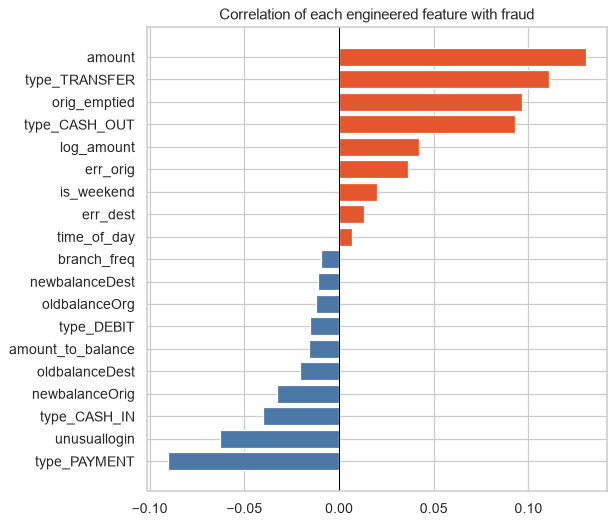

In [25]:
# Correlation heatmap of the engineered features with the label
corr_fe = X.assign(is_fraud=y).corr()["is_fraud"].drop("is_fraud").sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(corr_fe.index, corr_fe.values, color=np.where(corr_fe.values > 0, PALETTE[1], PALETTE[0]))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Correlation of each engineered feature with fraud")
plt.tight_layout()
plt.show()

### Feature scaling
Distance- and gradient-based models (logistic regression, One-Class SVM, autoencoder) are sensitive to the
size of the numbers. Two standard scalers from the EDA notebook:
* `StandardScaler` -> mean 0, standard deviation 1
* `MinMaxScaler` -> range 0 to 1

Money columns are first compressed with `arcsinh` (a signed log: it works for negative errors too).

In [26]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

demo = np.arcsinh(X[["amount", "oldbalanceOrg", "err_orig"]])
scaled = pd.concat({
    "raw (describe)": X[["amount", "oldbalanceOrg", "err_orig"]].describe().loc[["mean", "std", "min", "max"]].T,
    "StandardScaler": pd.DataFrame(StandardScaler().fit_transform(demo), columns=demo.columns).describe().loc[["mean", "std", "min", "max"]].T,
    "MinMaxScaler": pd.DataFrame(MinMaxScaler().fit_transform(demo), columns=demo.columns).describe().loc[["mean", "std", "min", "max"]].T,
}, axis=1).round(2)
scaled

raw (describe)                                      StandardScaler                  MinMaxScaler                
                        mean         std         min          max           mean  std   min   max         mean   std  min  max
amount             104901.59   270637.40        2.39  10000000.00            0.0  1.0 -4.37  3.09         0.59  0.13  0.0  1.0
oldbalanceOrg      883697.86  2124553.37        0.00  12900000.00            0.0  1.0 -1.60  1.43         0.53  0.33  0.0  1.0
err_orig          -125835.13   264599.39 -3776389.09       181.66            0.0  1.0 -1.51  2.16         0.41  0.27  0.0  1.0

## 5. Supervised fraud models

**Split:** 75% train / 25% test, `stratify=y` so both parts keep the same fraud rate.
**Imbalance:** only ~0.7% fraud, so every model uses *class weights* (a fraud row counts more than a legit
row). **Evaluation:** 5-fold stratified cross-validation on the training part, then one honest check on the
untouched test part. With only ~17 fraud cases in the test part, the cross-validated numbers are the more
reliable ones.

| Metric | Question it answers |
|--------|--------------------|
| Precision | Of the transactions we flagged, how many were really fraud? |
| Recall | Of all real frauds, how many did we catch? |
| F1 | Balance of precision and recall |
| ROC-AUC | How well are frauds ranked above legit overall? |
| PR-AUC | Same, but focused on the rare class (the most honest metric for fraud) |

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.tree import DecisionTreeClassifier

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print(f"train: {len(X_train):,} rows, {y_train.sum()} fraud   |   test: {len(X_test):,} rows, {y_test.sum()} fraud")

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

MODELS = {
    "Logistic Regression": Pipeline([
        ("log", ColumnTransformer([("arcsinh", FunctionTransformer(np.arcsinh), LOG_COLS)], remainder="passthrough")),
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_leaf_nodes=15,
                                                        min_samples_leaf=20, l2_regularization=1.0,
                                                        class_weight="balanced", random_state=RANDOM_STATE),
}

train: 7,593 rows, 51 fraud   |   test: 2,532 rows, 17 fraud


**Optional: XGBoost and LightGBM.** The project plan names them. They are not part of scikit-learn, so this
cell adds them only if they are installed (`pip install xgboost lightgbm`); otherwise it is skipped and the
scikit-learn Gradient Boosting model (the same algorithm family as LightGBM) is used.

In [28]:
neg_pos = float((y_train == 0).sum() / (y_train == 1).sum())
try:
    from xgboost import XGBClassifier
    MODELS["XGBoost"] = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                                      scale_pos_weight=neg_pos, eval_metric="aucpr", random_state=RANDOM_STATE, n_jobs=-1)
    print("XGBoost added")
except ImportError:
    print("xgboost not installed -> skipped")
try:
    from lightgbm import LGBMClassifier
    MODELS["LightGBM"] = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, scale_pos_weight=neg_pos,
                                        random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
    print("LightGBM added")
except ImportError:
    print("lightgbm not installed -> skipped")

xgboost not installed -> skipped
lightgbm not installed -> skipped


In [29]:
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "precision": "precision", "recall": "recall", "f1": "f1"}


def best_f1_threshold(y_true, proba):
    """Probability cut-off that maximises F1 (found on out-of-fold predictions, never on the test set)."""
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    near_best = np.flatnonzero(f1 >= 0.98 * np.nanmax(f1))       # all cut-offs that are (almost) equally good
    return float(t[near_best[len(near_best) // 2]])               # middle of that plateau: more stable than its edge


results, test_proba, thresholds, fitted = [], {}, {}, {}
for name, model in MODELS.items():
    cv_res = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    oof = cross_val_predict(model, X_train, y_train, cv=CV, method="predict_proba", n_jobs=-1)[:, 1]
    thr = best_f1_threshold(y_train, oof)
    model.fit(X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= thr).astype(int)
    fitted[name], test_proba[name], thresholds[name] = model, p, thr
    results.append({
        "model": name,
        "cv_roc_auc": cv_res["test_roc_auc"].mean(), "cv_pr_auc": cv_res["test_pr_auc"].mean(),
        "cv_pr_auc_std": cv_res["test_pr_auc"].std(),
        "test_roc_auc": roc_auc_score(y_test, p), "test_pr_auc": average_precision_score(y_test, p),
        "threshold": thr, "test_precision": precision_score(y_test, pred, zero_division=0),
        "test_recall": recall_score(y_test, pred), "test_f1": f1_score(y_test, pred),
    })

sup_table = pd.DataFrame(results).set_index("model").round(3).sort_values("cv_pr_auc", ascending=False)
sup_table

,cv_roc_auc,cv_pr_auc,cv_pr_auc_std,test_roc_auc,test_pr_auc,threshold,test_precision,test_recall,test_f1
model,,,,,,,,,
Logistic Regression,0.990,0.964,0.044,0.999,0.963,0.945,1.0,0.882,0.938
Gradient Boosting,0.999,0.962,0.059,1.000,1.000,0.966,1.0,1.000,1.000
Random Forest,0.999,0.960,0.054,1.000,1.000,0.303,1.0,1.000,1.000
Decision Tree,0.970,0.932,0.075,1.000,1.000,1.000,1.0,1.000,1.000


**How to read it:** `cv_*` columns are 5-fold cross-validated on the training data (more stable);
`test_*` columns are the single hold-out test. The `threshold` is the probability above which a transaction
is flagged. It was tuned for F1 on out-of-fold predictions, not on the test data.

**Two cautions before celebrating:**
1. The test set holds only 17 fraud cases, and the best models are within one standard deviation of each other
   in cross-validation (`cv_pr_auc_std`). Differences between them are not statistically meaningful; the notebook
   simply deploys the one with the best cross-validated PR-AUC.
2. This is a synthetic, simulation-style dataset in which fraud follows clean rules (money leaves the account
   through a TRANSFER or CASH_OUT and the balance changes follow a simple pattern). Real bank data is messier,
   so expect lower scores in production.

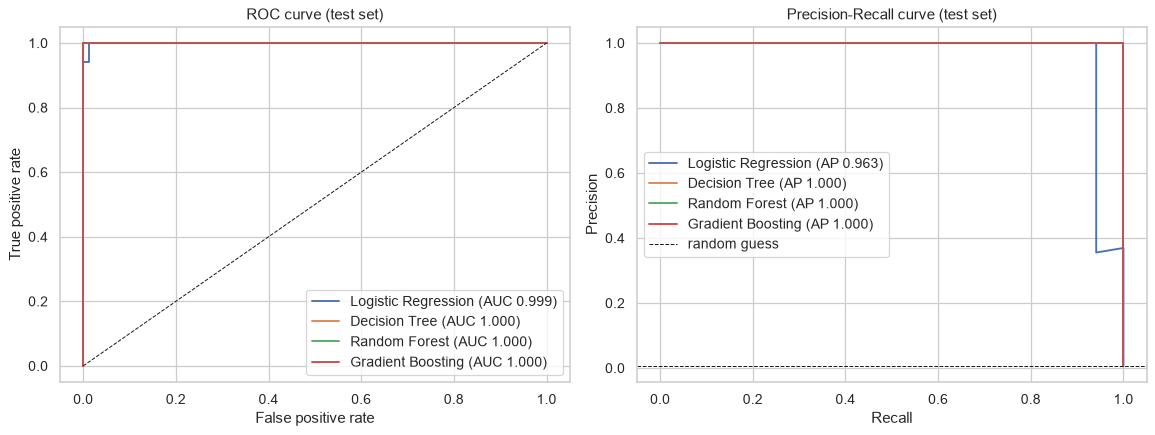

In [30]:
# ROC and Precision-Recall curves on the test set
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in test_proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    ax[1].plot(rc, pr, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set(title="ROC curve (test set)", xlabel="False positive rate", ylabel="True positive rate")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=0.8, label="random guess")
ax[1].set(title="Precision-Recall curve (test set)", xlabel="Recall", ylabel="Precision")
ax[0].legend(); ax[1].legend()
plt.tight_layout()
plt.show()

Deployed model: Logistic Regression   threshold: 0.945
Caught 15 of 17 frauds (recall 88%), with 0 false alarms out of 2,515 legit transactions.


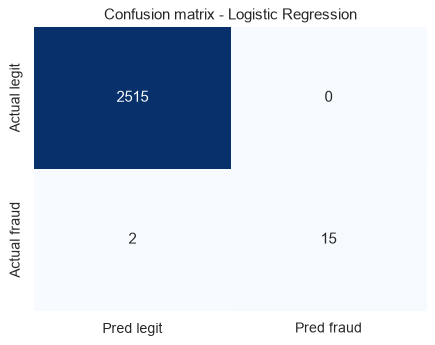

In [31]:
# Pick the deployed model: best cross-validated PR-AUC
BEST = sup_table.index[0]
DEPLOYED = fitted[BEST]
THRESHOLD = thresholds[BEST]
proba_best = test_proba[BEST]
pred_best = (proba_best >= THRESHOLD).astype(int)
cm = confusion_matrix(y_test, pred_best)
tn, fp, fn, tp = cm.ravel()
print(f"Deployed model: {BEST}   threshold: {THRESHOLD:.3f}")
print(f"Caught {tp} of {tp + fn} frauds (recall {tp / max(tp + fn, 1):.0%}), with {fp} false alarms out of {tn + fp:,} legit transactions.")

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Pred legit", "Pred fraud"], yticklabels=["Actual legit", "Actual fraud"])
ax.set_title(f"Confusion matrix - {BEST}")
plt.tight_layout()
plt.show()

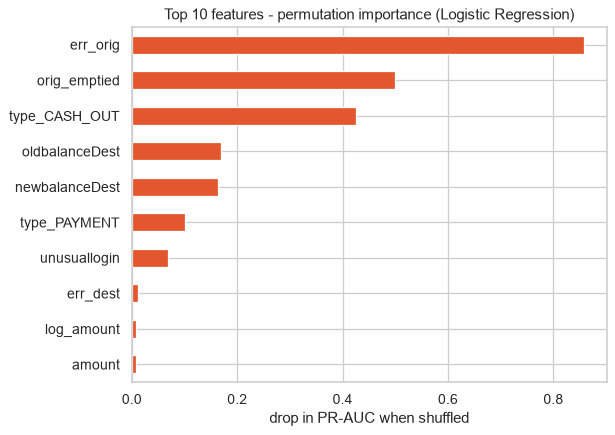

In [32]:
# What drives the model? Permutation importance = drop in PR-AUC when one feature is shuffled
from sklearn.inspection import permutation_importance

imp = permutation_importance(DEPLOYED, X_test, y_test, scoring="average_precision", n_repeats=10,
                             random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5))
importance.head(10).iloc[::-1].plot.barh(color=PALETTE[1], ax=ax)
ax.set_title(f"Top 10 features - permutation importance ({BEST})")
ax.set_xlabel("drop in PR-AUC when shuffled")
plt.tight_layout()
plt.show()

**What drives the model:** the top features are the engineered balance checks (`err_orig`, `orig_emptied`) and the
transaction type. The raw correlation heatmap in 3.4 could not show this, which is exactly why Section 4
builds those features.

### Is the model learning anything on the other datasets? (benchmark)
The same cross-validated test on all four datasets with one gradient-boosting model and each dataset's own
columns (IDs removed; dates become weekday/month). A ROC-AUC of **0.5 = random guessing**.

In [33]:
def benchmark_matrix(name):
    df, cfg = CLEAN[name], DATASETS[name]
    if name == "bank":
        return X, y
    feats = df.drop(columns=cfg["id_cols"] + ["is_fraud"]).copy()
    for c in list(feats.columns):
        if pd.api.types.is_datetime64_any_dtype(feats[c]):
            feats[f"{c}_weekday"] = feats[c].dt.dayofweek
            feats[f"{c}_month"] = feats[c].dt.month
            feats = feats.drop(columns=c)
        elif not pd.api.types.is_numeric_dtype(feats[c]):
            feats[c] = feats[c].astype("category")
    return feats, df["is_fraud"]


bench_rows = []
for name in CLEAN:
    Xb, yb = benchmark_matrix(name)
    gb = HistGradientBoostingClassifier(categorical_features="from_dtype", class_weight="balanced",
                                        max_iter=100, random_state=RANDOM_STATE)
    r = cross_validate(gb, Xb, yb, cv=CV, scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"}, n_jobs=-1)
    bench_rows.append({"dataset": name, "rows": len(Xb), "fraud_rate_%": round(100 * yb.mean(), 2),
                       "cv_roc_auc": r["test_roc_auc"].mean(), "cv_roc_auc_std": r["test_roc_auc"].std(),
                       "cv_pr_auc": r["test_pr_auc"].mean(), "random_pr_auc": yb.mean()})
bench = pd.DataFrame(bench_rows).set_index("dataset").round(3)
bench

,rows,fraud_rate_%,cv_roc_auc,cv_roc_auc_std,cv_pr_auc,random_pr_auc
dataset,,,,,,
credit_card,100000,1.00,0.486,0.018,0.010,0.010
financial,5000,9.64,0.707,0.041,0.296,0.096
synthetic,50000,32.13,0.498,0.007,0.322,0.321
bank,10125,0.67,0.987,0.025,0.964,0.007


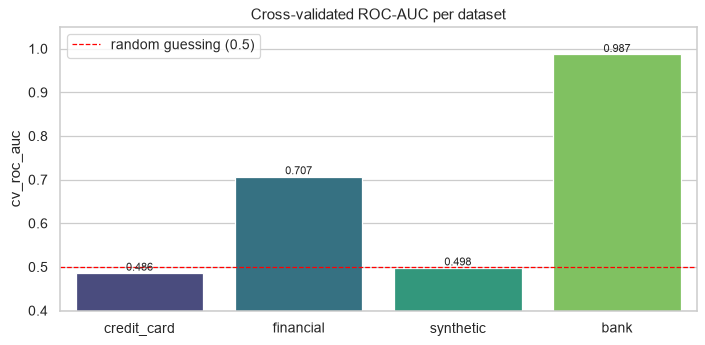

In [34]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = sns.barplot(x=bench.index, y=bench["cv_roc_auc"], hue=bench.index, palette="viridis", legend=False, ax=ax)
ax.axhline(0.5, color="red", ls="--", lw=1, label="random guessing (0.5)")
annotate_bars(ax, "{:.3f}")
ax.set_ylim(0.4, 1.05)
ax.set_title("Cross-validated ROC-AUC per dataset")
ax.set_xlabel(""); ax.legend()
plt.tight_layout()
plt.show()

**Conclusion:** the bank dataset is highly learnable, the financial dataset moderately, and the credit-card and
synthetic datasets sit at 0.5, so their labels cannot be predicted from the available columns. This is a
finding about the *data*, not a bug in the models. In a real project we would go back to the data owner
for more informative columns (merchant history, device fingerprints, velocity features, etc.).

## 6. Unsupervised anomaly detection
These models never see the fraud label during training. They learn what a *normal* transaction looks like
and flag whatever is different. That is how new, never-seen fraud types are caught in practice.
* **Isolation Forest** - anomalies are easy to isolate with random splits.
* **One-Class SVM** - learns a boundary around normal data.
* **Autoencoder** - a small neural network that compresses and rebuilds normal transactions; a large
  *reconstruction error* means "this does not look normal". (Built with scikit-learn's `MLPRegressor`;
  a TensorFlow/Keras autoencoder follows the same idea.)

In [35]:
from sklearn.ensemble import IsolationForest
from sklearn.neural_network import MLPRegressor
from sklearn.svm import OneClassSVM


def to_log_space(frame):
    z = frame.copy()
    z[LOG_COLS] = np.arcsinh(z[LOG_COLS])
    return z


scaler_u = StandardScaler().fit(to_log_space(X_train))
Z_train = scaler_u.transform(to_log_space(X_train))
Z_test = scaler_u.transform(to_log_space(X_test))
Z_normal = Z_train[(y_train == 0).to_numpy()]               # only legit rows (OC-SVM and autoencoder)

iso = IsolationForest(n_estimators=300, contamination=float(y_train.mean()), random_state=RANDOM_STATE).fit(Z_train)
iso_score = -iso.score_samples(Z_test)

rs = np.random.default_rng(RANDOM_STATE)
oc_rows = rs.choice(len(Z_normal), size=min(3000, len(Z_normal)), replace=False)
ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.02).fit(Z_normal[oc_rows])
oc_score = -ocsvm.decision_function(Z_test)

ae = MLPRegressor(hidden_layer_sizes=(8, 3, 8), activation="relu", max_iter=300, random_state=RANDOM_STATE).fit(Z_normal, Z_normal)
ae_score = ((ae.predict(Z_test) - Z_test) ** 2).mean(axis=1)

# Isolation-Forest anomaly score -> 0-100 percentile of the TRAINING data (100 = most unusual).
# The dashboard shows this number next to the fraud probability, so it is saved with the model.
ANOM_Q = np.quantile(-iso.score_samples(Z_train), np.linspace(0, 1, 101))


def anomaly_pct(frame):
    raw = -iso.score_samples(scaler_u.transform(to_log_space(frame[FEATURES])))
    return np.interp(raw, ANOM_Q, np.linspace(0, 100, len(ANOM_Q)))


unsup_scores = {"Isolation Forest": iso_score, "One-Class SVM": oc_score, "Autoencoder (MLP)": ae_score}
unsup_table = pd.DataFrame({
    n: {"test_roc_auc": roc_auc_score(y_test, s), "test_pr_auc": average_precision_score(y_test, s)}
    for n, s in unsup_scores.items()
}).T.round(3)
unsup_table.loc[f"(reference) {BEST}, supervised"] = [round(roc_auc_score(y_test, proba_best), 3),
                                                      round(average_precision_score(y_test, proba_best), 3)]
unsup_table

,test_roc_auc,test_pr_auc
Isolation Forest,0.953,0.113
One-Class SVM,0.973,0.445
Autoencoder (MLP),0.986,0.328
"(reference) Logistic Regression, supervised",0.999,0.963


Unsupervised models are weaker than the supervised model here, as expected (they get no labels), but they
still rank frauds far above random and need no labelled history. In production the two are combined:
the supervised model for known fraud patterns, the anomaly score as an early-warning net for new ones.

## 7. Graph-based analysis
Fraud is often organised: money flows from victim accounts into a few receiving accounts. We build a
directed graph (sender -> receiver) and look at the fraud edges.

In [37]:
%pip install networkx
import networkx as nx

fraud_edges = bank[bank["is_fraud"] == 1][["nameOrig", "nameDest", "amount"]]
G = nx.DiGraph()
for _, r in fraud_edges.iterrows():
    G.add_edge(r["nameOrig"], r["nameDest"], amount=r["amount"])

dest = bank.groupby("nameDest").agg(received_txns=("txn_id", "size"), fraud_txns=("is_fraud", "sum"), total_received=("amount", "sum"))
dest["fraud_txns"] = dest["fraud_txns"].astype(int)
print(f"Fraud graph: {G.number_of_nodes()} accounts, {G.number_of_edges()} fraudulent transfers")
print("Receiving accounts that got more than one fraudulent transfer:", int((dest["fraud_txns"] > 1).sum()))
dest.sort_values(["fraud_txns", "total_received"], ascending=False).head(5).round(0)

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   -------------- ------------------------- 0.8/2.1 MB 2.3 MB/s eta 0:00:01
   ---------------------------------- ----- 1.8/2.1 MB 3.3 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 3.3 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Fraud graph: 135 accounts, 68 fraudulent transfers
Receiving accounts that got more than one fraudulent transfer: 1


,received_txns,fraud_txns,total_received
nameDest,,,
C410033330,6,2,418555.0
C766681183,22,1,17972766.0
C932583850,36,1,12457287.0
C945327594,1,1,10000000.0
C991505714,19,1,9490716.0


67 separate groups; 1 groups with more than one sender or receiver


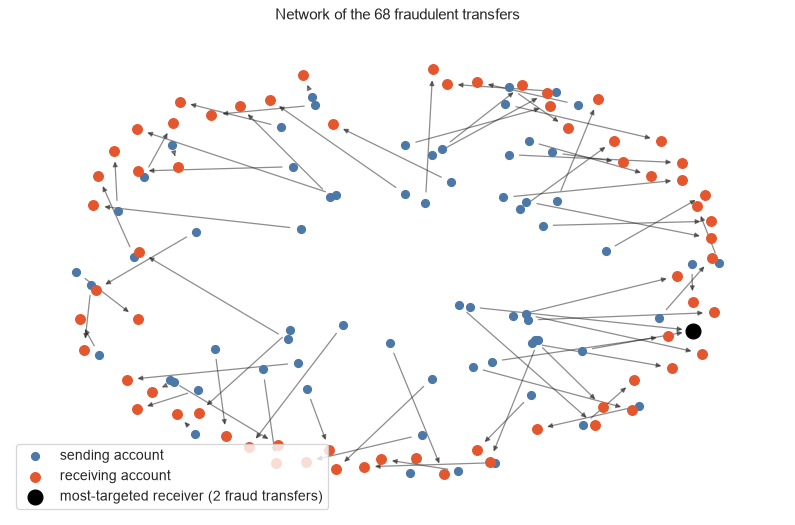

In [38]:
# draw the largest connected pieces of the fraud network
UG = G.to_undirected()
components = sorted(nx.connected_components(UG), key=len, reverse=True)
multi = [c for c in components if len(c) > 2]
print(f"{len(components)} separate groups; {len(multi)} groups with more than one sender or receiver")

fig, ax = plt.subplots(figsize=(9, 6))
pos = nx.spring_layout(G, seed=RANDOM_STATE, k=0.35)
receivers = {v for u, v in G.edges}
hub = dest.sort_values("fraud_txns", ascending=False).index[0]               # receiver with the most fraud
nx.draw_networkx_edges(G, pos, alpha=0.5, arrows=True, arrowsize=8, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=[n for n in G if n not in receivers], node_color=PALETTE[0], node_size=40,
                       label="sending account", ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=[n for n in receivers if n != hub], node_color=PALETTE[1], node_size=60,
                       label="receiving account", ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=[hub], node_color="black", node_size=140,
                       label=f"most-targeted receiver ({int(dest.loc[hub, 'fraud_txns'])} fraud transfers)", ax=ax)
ax.set_title("Network of the 68 fraudulent transfers")
ax.legend(loc="lower left")
ax.axis("off")
plt.tight_layout()
plt.show()

In this dataset almost every fraudulent transfer goes to a *different* receiving account (only one receiver
appears twice), so there is no obvious mule network here. With real data that has repeated accounts, the same code (receiving accounts with many fraud
edges, tightly connected groups) is how fraud rings are found.

## 8. Gradient descent
Gradient descent is how most models learn: repeatedly step *downhill* on the loss function.
`x = x - learning_rate * gradient`.

### 8.1 The classic demo: minimise `f(x) = x²` (gradient = `2x`)

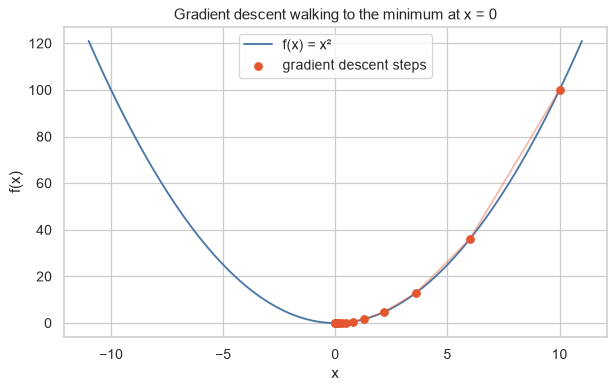

start x = 10  ->  after 15 steps x = 0.00470


In [39]:
f = lambda x: x ** 2
grad = lambda x: 2 * x

x, lr = 10.0, 0.2
path = [x]
for _ in range(15):
    x = x - lr * grad(x)
    path.append(x)

xs = np.linspace(-11, 11, 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(xs, f(xs), color="#4C78A8", label="f(x) = x²")                                # function / line plot
ax.scatter(path, [f(p) for p in path], color=PALETTE[1], zorder=3, label="gradient descent steps")   # scatter points
ax.plot(path, [f(p) for p in path], color=PALETTE[1], alpha=0.4)
ax.set(title="Gradient descent walking to the minimum at x = 0", xlabel="x", ylabel="f(x)")
ax.legend()
plt.tight_layout()
plt.show()
print(f"start x = 10  ->  after 15 steps x = {path[-1]:.5f}")

### 8.2 The same idea on real data: logistic regression trained by hand
Loss = weighted *log loss*. We implement the update rule in plain NumPy and watch the loss fall,
then compare with scikit-learn's solver.

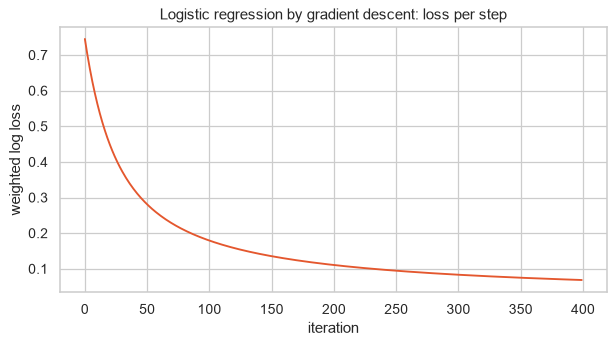

loss: 0.745 -> 0.068
test PR-AUC  manual gradient descent: 0.972   scikit-learn LogisticRegression: 0.963


In [40]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))


pos_weight = float(np.sqrt((y_train == 0).sum() / (y_train == 1).sum()))     # soften the imbalance weight
yt = y_train.to_numpy().astype(float)
w, b = np.zeros(Z_train.shape[1]), 0.0
learning_rate, losses = 0.1, []
sample_w = np.where(yt == 1, pos_weight, 1.0)

for step in range(400):
    p = sigmoid(Z_train @ w + b)
    loss = -np.mean(sample_w * (yt * np.log(p + 1e-9) + (1 - yt) * np.log(1 - p + 1e-9)))
    losses.append(loss)
    err = sample_w * (p - yt)
    w -= learning_rate * (Z_train.T @ err) / len(yt)
    b -= learning_rate * err.mean()

manual_test = sigmoid(Z_test @ w + b)
sk_lr = LogisticRegression(class_weight="balanced", max_iter=2000).fit(Z_train, y_train)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(losses, color=PALETTE[1])
ax.set(title="Logistic regression by gradient descent: loss per step", xlabel="iteration", ylabel="weighted log loss")
plt.tight_layout()
plt.show()
print(f"loss: {losses[0]:.3f} -> {losses[-1]:.3f}")
print(f"test PR-AUC  manual gradient descent: {average_precision_score(y_test, manual_test):.3f}   "
      f"scikit-learn LogisticRegression: {average_precision_score(y_test, sk_lr.predict_proba(Z_test)[:, 1]):.3f}")

## 9. Real-time monitoring simulation

### 9.1 Micro-batch stream with alerts
The project plan uses Apache Kafka / Spark Streaming. Those need servers, so here we **simulate** the same
flow in plain Python: the test transactions arrive in time order in small batches, each batch is scored by
the deployed model, and anything above the threshold raises an alert. The reference Kafka/PySpark code
(typos fixed) is in Section 9.4.

In [41]:
meta_cols = ["txn_id", "date", "type", "branch", "amount", "nameOrig", "nameDest"]
stream = X_test.join(bank[["txn_id", "date", "type", "branch", "nameOrig", "nameDest"]]).assign(is_fraud=y_test).sort_values("date")

BATCH = 250
alert_frames, stream_log = [], []
for b, start in enumerate(range(0, len(stream), BATCH)):
    batch = stream.iloc[start:start + BATCH]
    score = DEPLOYED.predict_proba(batch[FEATURES])[:, 1]
    anom = anomaly_pct(batch)
    flagged = batch.loc[score >= THRESHOLD, meta_cols + ["is_fraud"]].assign(score=score[score >= THRESHOLD], anomaly_pct=anom[score >= THRESHOLD], batch=b)
    alert_frames.append(flagged)
    stream_log.append({"batch": b, "txns": len(batch), "alerts": len(flagged),
                       "real_frauds": int(batch["is_fraud"].sum()), "frauds_caught": int(flagged["is_fraud"].sum()),
                       "mean_anomaly_pct": float(anom.mean())})

alerts = pd.concat(alert_frames, ignore_index=True)
stream_log = pd.DataFrame(stream_log)
print(f"{len(stream):,} transactions in {len(stream_log)} micro-batches  ->  {len(alerts)} alerts, "
      f"{int(alerts['is_fraud'].sum())} of them real fraud")
stream_log

2,532 transactions in 11 micro-batches  ->  15 alerts, 15 of them real fraud


,batch,txns,alerts,real_frauds,frauds_caught,mean_anomaly_pct
0,0,250,3,4,3,47.550745
1,1,250,5,5,5,53.842431
2,2,250,0,1,0,58.844755
3,3,250,1,1,1,55.563292
4,4,250,1,1,1,47.065385
5,5,250,1,1,1,47.972204
6,6,250,2,2,2,45.867052
7,7,250,1,1,1,55.949589
8,8,250,1,1,1,46.066455
9,9,250,0,0,0,48.134122


In [42]:
alerts.sort_values("score", ascending=False).head(8).round({"score": 3, "amount": 0})

,txn_id,date,type,branch,amount,nameOrig,nameDest,is_fraud,score,anomaly_pct,batch
6,BNK-001114,2018-01-06,TRANSFER,Italia,1277213.0,C1334405552,C431687661,1,1.0,99.248033,1
12,BNK-002134,2018-01-11,CASH_OUT,Argentina,1096187.0,C77163673,C644345897,1,1.0,99.359711,6
0,BNK-002144,2018-01-03,CASH_OUT,El Salvador,120075.0,C1174000532,C410033330,1,1.0,97.176217,0
11,BNK-001113,2018-01-11,TRANSFER,Brasil,20128.0,C137533655,C1848415041,1,1.0,93.299021,6
3,BNK-001127,2018-01-05,TRANSFER,Cuba,86070.0,C1844941220,C1191544932,1,1.0,89.008051,1
2,BNK-001122,2018-01-05,TRANSFER,Azerbaiyan,10539.0,C1134864869,C118648358,1,1.0,92.484948,0
7,BNK-008182,2018-01-06,CASH_OUT,Australia,262435.0,C383717053,C380242442,1,1.0,99.033442,1
9,BNK-001130,2018-01-09,TRANSFER,Arabia Saudi,10119.0,C1775746074,C746009679,1,1.0,89.130445,4


### 9.2 Alerting (email)
`send_alert_email` builds the alert message and sends it by SMTP. By default it runs in **dry-run mode**
(it only prints the email), so no password is ever stored in code. To send real emails, set the
environment variables `ALERT_SENDER`, `ALERT_RECIPIENT` and `ALERT_APP_PASSWORD` (for Gmail this must be an
*App Password*, not your normal password) and call it with `dry_run=False`.

In [43]:
import smtplib
from email.message import EmailMessage


def send_alert_email(txn, dry_run=True):
    sender = os.environ.get("ALERT_SENDER", "alerts@example.com")
    recipient = os.environ.get("ALERT_RECIPIENT", "fraud-team@example.com")
    msg = EmailMessage()
    msg["Subject"] = f"FRAUD ALERT {txn['txn_id']} - risk score {txn['score']:.2f}"
    msg["From"], msg["To"] = sender, recipient
    msg.set_content(
        f"Suspicious transaction detected\n\n"
        f"Transaction ID : {txn['txn_id']}\nType           : {txn['type']}\n"
        f"Amount         : {txn['amount']:,.2f}\nBranch         : {txn['branch']}\n"
        f"Risk score     : {txn['score']:.3f}\n"
    )
    if dry_run:
        print(f"[DRY RUN] To: {recipient}\nSubject: {msg['Subject']}\n\n{msg.get_content()}")
        return
    with smtplib.SMTP("smtp.gmail.com", 587) as server:
        server.starttls()
        server.login(sender, os.environ["ALERT_APP_PASSWORD"])
        server.send_message(msg)


send_alert_email(alerts.sort_values("score", ascending=False).iloc[0])

[DRY RUN] To: fraud-team@example.com
Subject: FRAUD ALERT BNK-001114 - risk score 1.00

Suspicious transaction detected

Transaction ID : BNK-001114
Type           : TRANSFER
Amount         : 1,277,212.77
Branch         : Italia
Risk score     : 1.000



### 9.3 Adaptive learning (online learning)
Fraud patterns change, so a model should keep learning from newly confirmed cases. `SGDClassifier.partial_fit`
updates a model batch by batch without retraining from scratch. We feed the training data in 10 chunks and
track the test PR-AUC after each one.

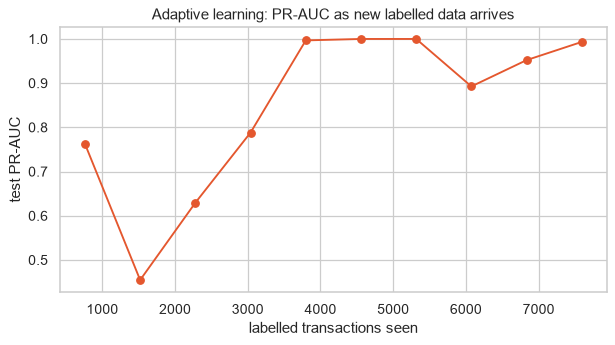

,chunk,labelled_txns_seen,test_pr_auc
0,1,760,0.763
1,2,1520,0.455
2,3,2280,0.630
3,4,3039,0.788
4,5,3798,0.997
5,6,4557,1.000
6,7,5316,1.000
7,8,6075,0.893
8,9,6834,0.952
9,10,7593,0.993


In [44]:
from sklearn.linear_model import SGDClassifier

online = SGDClassifier(loss="log_loss", alpha=1e-4, class_weight={0: 1.0, 1: neg_pos ** 0.5}, random_state=RANDOM_STATE)
chunk_idx = np.array_split(np.arange(len(Z_train)), 10)
online_curve = []
for i, idx in enumerate(chunk_idx, start=1):
    online.partial_fit(Z_train[idx], y_train.to_numpy()[idx], classes=[0, 1])
    online_curve.append({"chunk": i, "labelled_txns_seen": sum(len(c) for c in chunk_idx[:i]),
                         "test_pr_auc": average_precision_score(y_test, online.decision_function(Z_test))})
online_curve = pd.DataFrame(online_curve)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(online_curve["labelled_txns_seen"], online_curve["test_pr_auc"], marker="o", color=PALETTE[1])
ax.set(title="Adaptive learning: PR-AUC as new labelled data arrives", xlabel="labelled transactions seen", ylabel="test PR-AUC")
plt.tight_layout()
plt.show()
online_curve.round(3)

The curve is jumpy because each chunk holds only about 5 fraud cases, so a single chunk can swing the model.
From chunk 5 onwards it stays high (roughly 0.90 to 1.00). In production this update step runs whenever
analysts confirm new fraud / not-fraud cases.

### 9.4 Reference code for a real Kafka / PySpark deployment (not run here)
These are the snippets from the project plan with the typos fixed and adapted to this dataset's columns.
They need a running Kafka broker / a Spark installation.

```python
# --- Kafka consumer ---
import json
import joblib
from kafka import KafkaConsumer

model = joblib.load("artifacts/model.joblib")
consumer = KafkaConsumer("transaction_stream", bootstrap_servers=["localhost:9092"])

for message in consumer:
    transaction = json.loads(message.value)                       # json.loads, not json/loads
    prediction = model.predict([transaction["features"]])
    if prediction[0] == 1:
        print(f"ALERT! Fraudulent transaction detected: {transaction}")
```

```python
# --- PySpark structured streaming ---
from pyspark.sql import SparkSession
from pyspark.sql.functions import hour
from pyspark.sql.types import StructType
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.classification import LogisticRegressionModel

spark = SparkSession.builder.appName("FraudDetectionSystem").getOrCreate()   # note the ()

schema = (StructType()
          .add("transaction_id", "integer").add("customer_id", "string")
          .add("amount", "double").add("timestamp", "timestamp")             # "timestamp", not "stimstamp"
          .add("location", "string").add("device", "string").add("is_fraud", "integer"))

transactions = (spark.readStream.schema(schema).option("maxFilesPerTrigger", 1).csv("streaming_input/"))
transactions = transactions.withColumn("hour", hour("timestamp"))

indexed = StringIndexer(inputCol="location", outputCol="loc_idx").fit(transactions).transform(transactions)
indexed = StringIndexer(inputCol="device", outputCol="dev_idx").fit(indexed).transform(indexed)

assembler = VectorAssembler(inputCols=["amount", "hour", "loc_idx", "dev_idx"], outputCol="features")  # outputCol (singular)
feature_df = assembler.transform(indexed)

model = LogisticRegressionModel.load("fraud_model")
predictions = model.transform(feature_df)
```

## 10. Save everything the dashboard needs
* `model.joblib` - the deployed model (scikit-learn pipeline/estimator)
* `meta.json` - feature list, threshold, encodings, dataset settings
* `metrics.json` - model comparison, curves, importance, benchmark
* `fraud_detection.db` - SQLite database: unified table, cleaned tables, model features, alerts

In [45]:
import joblib


def thin(a, n=150):
    a = np.asarray(a, dtype=float)
    idx = np.unique(np.linspace(0, len(a) - 1, min(n, len(a))).astype(int))
    return a[idx].round(5).tolist()


curves = {}
for name, p in {**test_proba, **{k: v for k, v in unsup_scores.items()}}.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    pr, rc, _ = precision_recall_curve(y_test, p)
    curves[name] = {"fpr": thin(fpr), "tpr": thin(tpr), "precision": thin(pr), "recall": thin(rc)}

metrics = {
    "primary_dataset": "bank",
    "deployed_model": BEST,
    "threshold": THRESHOLD,
    "split": {"train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
              "train_frauds": int(y_train.sum()), "test_frauds": int(y_test.sum())},
    "supervised": sup_table.reset_index().to_dict(orient="records"),
    "unsupervised": unsup_table.reset_index().rename(columns={"index": "model"}).to_dict(orient="records"),
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "curves": curves,
    "feature_importance": importance.round(5).to_dict(),
    "benchmark": bench.reset_index().to_dict(orient="records"),
    "signal_tests": signal_summary.reset_index().to_dict(orient="records"),
}
meta = {
    "features": FEATURES, "types": TYPES, "tod_map": TOD_MAP, "log_cols": LOG_COLS,
    "threshold": THRESHOLD, "model_name": BEST,
    "branch_freq": BRANCH_FREQ.round(6).to_dict(),
    "anomaly_quantiles": ANOM_Q.round(6).tolist(),
    "datasets": {k: {"table": f"{k}_clean", "label": v["label"], "amount": v["amount"],
                     "category": v["category"], "id_cols": v["id_cols"]} for k, v in DATASETS.items()},
}
to_py = lambda o: o.item() if hasattr(o, "item") else str(o)
(ARTIFACTS / "metrics.json").write_text(json.dumps(metrics, indent=1, default=to_py))
(ARTIFACTS / "meta.json").write_text(json.dumps(meta, indent=1, default=to_py))
joblib.dump(DEPLOYED, ARTIFACTS / "model.joblib")
joblib.dump({"model": iso, "scaler": scaler_u}, ARTIFACTS / "anomaly_model.joblib")

# model-ready table + alerts into the same SQLite database
features_table = (X.join(bank[["txn_id", "date", "type", "branch", "nameOrig", "nameDest"]])
                  .assign(is_fraud=y, split=np.where(X.index.isin(X_test.index), "test", "train")))
conn = sqlite3.connect(DB_PATH)
features_table.to_sql("primary_features", conn, if_exists="replace", index=False)
alerts.to_sql("alerts", conn, if_exists="replace", index=False)
stream_log.to_sql("stream_log", conn, if_exists="replace", index=False)
conn.commit()
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", conn)["name"].tolist()
conn.close()

print("Saved to", ARTIFACTS.resolve())
for f in sorted(ARTIFACTS.iterdir()):
    print(f"  {f.name:22s} {f.stat().st_size / 1024:>10,.0f} KB")
print("SQLite tables:", tables)

Saved to C:\Users\Manas\Desktop\fraud_project_deliverable\fraud_project\artifacts
  anomaly_model.joblib        4,785 KB
  fraud_detection.db         28,392 KB
  meta.json                       6 KB
  metrics.json                   33 KB
  model.joblib                    4 KB
SQLite tables: ['alerts', 'bank_clean', 'credit_card_clean', 'financial_clean', 'primary_features', 'stream_log', 'synthetic_clean', 'transactions']


## 11. Summary and future work

**What was built:** a cleaned, SQLite-backed multi-dataset pipeline; EDA with the full graph toolkit;
engineered features; four supervised models (plus XGBoost/LightGBM when installed) and three unsupervised
detectors; graph analysis; gradient descent from scratch; a micro-batch monitoring simulation with email
alerts and online learning; and the artifacts for the dashboard.

**Key takeaways**
1. Judge fraud models with PR-AUC / recall / precision, never accuracy.
2. Always check for **data leakage** (`isFraud - Copy` was a perfect copy of the label).
3. Not every dataset is learnable: the credit-card and synthetic files carry no signal, and combining
   them with good data would only add noise.
4. Do not delete outliers blindly; in fraud detection they are often the signal.

**Future enhancements** (from the project plan, not implemented here): AI-driven credit risk scoring,
a blockchain-based fraud-prevention layer, and mobile-app push alerts.

**Next step:** run `streamlit run app.py` in this folder to explore everything interactively.